# 01. Interactive Fiction, Visual Novels & Narrative RPGs

> 💡 **How to Read This Guide (Beginner-Friendly Mode)**  
> **You do not need to read any code to follow this walkthrough.** Every code cell in this notebook is **collapsed by default** so you can focus on the story, the game-design concepts, and the live outputs below each section.  
> - **Want to inspect how a feature is built?** Click any collapsed code cell (or choose **View → Expand All Code** in JupyterLab) to reveal a short, clean Python snippet.  
> - **Preset:** `InteractiveFictionPreset(include_background_edges=True)` · **LLM:** DeepSeek Flash (`deepseek-flash`, with automatic offline fallback).

---

## What Problem Are We Solving?

Imagine you are building an AI-powered RPG or visual novel—like *Baldur's Gate*, *Disco Elysium*, or a Ren'Py game—where an LLM writes the narration and roleplays the NPCs.

Most AI memory tools (`mem0`, `zep`, `langmem`) treat memory like a **single linear chat log** with wall-clock timestamps. That works for a customer-support chatbot, but it **breaks down immediately in narrative games**:

1. **Mind-Reading NPCs (Metagaming):** If you paste the whole story log into the prompt and ask the AI to "pretend" a guard didn't hear a secret conversation, the AI will routinely slip up and leak the secret anyway.
2. **Save-Scumming & Branching Routes:** Players reload earlier saves and try different choices all the time. A flat chat log cannot cleanly rewind or split into parallel story routes without corrupting memory.
3. **Flashbacks Corrupting the Present:** If your game plays a flashback from 10 years ago when two rivals were best friends, naive AI memory overwrites their current relationship and thinks they are friends *today*.
4. **Generic "Chatbot" Voices (Voice Drift):** Over dozens of turns, if bland AI dialogue gets fed back into memory as examples, every character slowly flattens into the same polite assistant voice.

---

## How `canonarc` Works at a High Level: The "Game Master's Binder"

Instead of stuffing everything into one giant chat transcript, `canonarc` works like a structured **Game Master's Binder** stored inside a single lightweight SQLite file. Every story turn advances a discrete step number (`Step 0`, `Step 10`, `Step 82`...) and organizes world knowledge into **6 clear layers ("Tiers")**:

| Layer | Everyday RPG Equivalent | What `canonarc` Tracks & Guarantees |
| :--- | :--- | :--- |
| **Tier 1** · Identity | **Character Sheets & Lore** | Permanent facts (`title`, `archetype`, whether something is a `character`, `location`, or `artifact`)—kept separate from temporary moods so lore never gets accidentally overwritten. |
| **Tier 2** · Relationships | **Affinity Graph & Inventory** | Directed relationships (Arthur can distrust Merlin `-0.6` while Merlin still trusts Arthur `+0.85`), who currently holds a quest item, and off-screen bonds (like Arthur's love for Queen Guinevere). |
| **Tier 3** · Live State | **Current Mood, Room & Secret Motives** | What is true *right now*, what changed recently (`furious — was calm`), and hidden agendas (`private_state`) that only the Narrator/GM can see. |
| **Tier 4** · Aliases | **Nicknames & Titles** | Automatically connects `"the old wizard"` → Merlin and `"His Majesty"` → Arthur so the engine never loses track of who is being referenced. |
| **Tier 5** · Voice Bank | **Curated Dialogue Style Guide** | Saves each character's *best* lines and filters out bland/out-of-character lines with a **2-stage quality gate**, matching examples to the current tone & formality. |
| **Tier 6** · Episodes | **Quest Log, Secrets, Lies & Flashbacks** | Records major plot events along with **who witnessed them**, **who was lied to**, **who was told later**, and **who forgot**—making NPC metagaming structurally impossible. |

### The 4-Step Game Turn Loop

Every turn in an AI RPG powered by `canonarc` follows the same clean loop:

```mermaid
flowchart LR
    A["💾 Save State<br/>(SQLite Timeline + Step t)"] --> B["1. LOOK UP SCENE<br/>Who is in the room?<br/>What does this POV know?"]
    B --> C["2. WRITE SCENE<br/>AI generates narration &<br/>in-character dialogue"]
    C --> D["3. FILTER DIALOGUE<br/>Harvest quotes & reject<br/>bland lines (2-Stage Gate)"]
    D --> E["4. UPDATE WORLD<br/>Save mood, trust, items &<br/>memories atomically"]
    E --> A
```

---

## Meet the Cast of Our Demo Campaign

Throughout this notebook, we will play through a branching **Arthurian dark-fantasy RPG** to see every feature in action:

- 👑 **King Arthur** (`char_arthur`) — Noble ruler, starts `calm` and deeply trusting of Merlin.
- 🧙 **Merlin** (`char_merlin`) — Court Wizard, starts `composed`, but carries a **hidden agenda** (`delay_prophecy_until_solstice`) and secretly carries the **Obsidian Dragon Seal**.
- ⚔️ **Mordred** (`char_mordred`) — Watchful, ambitious young knight stationed outside in the **Castle Courtyard** (blind to private council secrets!).
- 🌹 **Queen Guinevere** (`char_guinevere`) — Off-screen royal ally in the **Royal Garden**, used to show how off-screen ties enrich a scene.
- 🐉 **Obsidian Dragon Seal** (`item_dragon_seal`) — A tracked quest artifact that changes hands during the story.

*(Expand the hidden Setup cell below only if you want to see imports, LLM configuration, and HTML/SVG rendering helpers.)*

In [1]:
#@title ⚙️ Setup & Display Helpers (click to inspect — safe to leave collapsed!)
import html
import json
import os
import tempfile
import time
import urllib.request
from pathlib import Path
from typing import Any

from IPython.display import HTML, SVG, display

from canonarc import (
    BaseEngineHooks,
    CachedDeltaExtractor,
    CanonArcEngine,
    EdgeDelta,
    EntityDelta,
    EntityRecord,
    EpisodeRecord,
    InformDelta,
    InteractiveFictionPreset,
    OpenAICompatibleExtractor,
    StepDelta,
    TimelineInfo,
    TokenUsage,
    VoiceExemplar,
    load_dotenv,
)

load_dotenv()

DEEPSEEK_API_KEY = os.environ.get("DEEPSEEK_API_KEY", "")
DEEPSEEK_BASE_URL = os.environ.get("DEEPSEEK_BASE_URL", "https://api.deepseek.com/v1").rstrip("/")
DEEPSEEK_MODEL = os.environ.get("DEEPSEEK_MODEL", "deepseek-flash")
HAS_LIVE_LLM = bool(DEEPSEEK_API_KEY and DEEPSEEK_API_KEY != "your_deepseek_api_key_here")

dialogue_llm_usage = TokenUsage()


def call_deepseek_flash(
    messages: list[dict[str, str]],
    *,
    temperature: float = 0.3,
    fallback_text: str = "",
) -> tuple[str, TokenUsage]:
    """Zero-dependency HTTP call to DeepSeek Flash with TokenUsage tracking and offline fallback."""
    if not HAS_LIVE_LLM:
        return fallback_text, TokenUsage()

    payload = json.dumps(
        {"model": DEEPSEEK_MODEL, "temperature": temperature, "messages": messages}
    ).encode("utf-8")
    req = urllib.request.Request(
        f"{DEEPSEEK_BASE_URL}/chat/completions",
        data=payload,
        headers={
            "Content-Type": "application/json",
            "Authorization": f"Bearer {DEEPSEEK_API_KEY}",
        },
        method="POST",
    )
    t0 = time.perf_counter()
    with urllib.request.urlopen(req, timeout=45) as resp:
        data = json.loads(resp.read().decode("utf-8"))
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    content = data["choices"][0]["message"]["content"].strip()
    raw_usage = data.get("usage", {})
    usage = TokenUsage(
        prompt_tokens=int(raw_usage.get("prompt_tokens", 0)),
        completion_tokens=int(raw_usage.get("completion_tokens", 0)),
        total_tokens=int(raw_usage.get("total_tokens", 0)),
        latency_ms=elapsed_ms,
        api_calls=1,
    )
    dialogue_llm_usage.add(usage)
    return content, usage


# --- Reusable Visual Renderers (keeps demo cells clean & focused on canonarc APIs) ---

def render_ab_comparison(naive_reply: str, pov_reply: str, leaked_naive: bool) -> None:
    display(HTML(f"""
<div style="display:grid;grid-template-columns:1fr 1fr;gap:14px;font-family:system-ui,-apple-system,sans-serif;margin:8px 0;">
  <div style="border:1px solid #fca5a5;background:#fef2f2;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#991b1b;margin-bottom:6px;">
      ❌ Without canonarc: Flat Story Log {'(LEAKED SECRET!)' if leaked_naive else '(Risky: Secret Exposed in Prompt)'}
    </div>
    <div style="font-size:12px;color:#7f1d1d;margin-bottom:8px;">
      Prompt accidentally included: <code>dragon prophecy</code>, <code>swore_silence_to_the_wyrm</code>
    </div>
    <blockquote style="margin:0;padding:10px;background:#fff;border-left:4px solid #dc2626;color:#1f2937;font-size:13px;line-height:1.5;">
      {html.escape(naive_reply)}
    </blockquote>
  </div>
  <div style="border:1px solid #86efac;background:#f0fdf4;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#166534;margin-bottom:6px;">
      ✅ With canonarc: Mordred POV Projection (Zero Leak Guaranteed)
    </div>
    <div style="font-size:12px;color:#14532d;margin-bottom:8px;">
      <code>pov_entity_ids=["char_mordred"]</code> → <strong>0 secret memories</strong>, <strong>hidden motives redacted</strong>
    </div>
    <blockquote style="margin:0;padding:10px;background:#fff;border-left:4px solid #16a34a;color:#1f2937;font-size:13px;line-height:1.5;">
      {html.escape(pov_reply)}
    </blockquote>
  </div>
</div>
"""))


def render_context_card(title: str, subtitle: str, formatted_context: str) -> None:
    display(HTML(f"""
<div style="font-family:system-ui,-apple-system,sans-serif;border:1px solid #e5e7eb;border-radius:10px;overflow:hidden;margin:8px 0;">
  <div style="background:#f8fafc;padding:10px 14px;border-bottom:1px solid #e5e7eb;">
    <div style="font-weight:700;color:#0f172a;font-size:14px;">{html.escape(title)}</div>
    <div style="font-size:12px;color:#475569;margin-top:2px;">{subtitle}</div>
  </div>
  <pre style="margin:0;padding:12px 14px;background:#ffffff;color:#1e293b;font-size:12.5px;line-height:1.55;white-space:pre-wrap;font-family:ui-monospace,SFMono-Regular,Menlo,monospace;">{html.escape(formatted_context)}</pre>
</div>
"""))


def render_gate_audit(rejections: list[dict[str, Any]], accepted: list[VoiceExemplar], fallback_note: str) -> None:
    rows = []
    for r in rejections:
        badge = (
            '<span style="background:#fee2e2;color:#991b1b;padding:2px 7px;border-radius:6px;font-weight:600;font-size:11.5px;">'
            f'REJECTED ({html.escape(r["stage"])})</span>'
        )
        rows.append(
            f"<tr><td style='padding:8px;border:1px solid #e5e7eb;'>{badge}</td>"
            f"<td style='padding:8px;border:1px solid #e5e7eb;'><code>{html.escape(r['text'][:72])}</code></td>"
            f"<td style='padding:8px;border:1px solid #e5e7eb;'>{html.escape(r['reason'])}</td></tr>"
        )
    for ex in accepted:
        badge = '<span style="background:#dcfce7;color:#166534;padding:2px 7px;border-radius:6px;font-weight:600;font-size:11.5px;">ACCEPTED</span>'
        rows.append(
            f"<tr><td style='padding:8px;border:1px solid #e5e7eb;'>{badge}</td>"
            f"<td style='padding:8px;border:1px solid #e5e7eb;'><code>{html.escape(ex.text[:72])}...</code></td>"
            f"<td style='padding:8px;border:1px solid #e5e7eb;'>speaker=<b>{html.escape(ex.speaker_id)}</b>, quality={ex.quality_score}, register={html.escape(str(ex.metadata.get('register')))}</td></tr>"
        )
    display(HTML(f"""
<table style="border-collapse:collapse;width:100%;font-family:system-ui,sans-serif;font-size:13px;">
  <thead>
    <tr style="background:#f3f4f6;text-align:left;">
      <th style="padding:8px;border:1px solid #e5e7eb;">Gate Outcome</th>
      <th style="padding:8px;border:1px solid #e5e7eb;">Dialogue Line</th>
      <th style="padding:8px;border:1px solid #e5e7eb;">Why / Saved Metadata</th>
    </tr>
  </thead>
  <tbody>{"".join(rows)}</tbody>
</table>
<p style="font-family:system-ui,sans-serif;font-size:12.5px;color:#4b5563;margin-top:8px;">
  <strong>Graceful Fallback Check:</strong> When asking for an <code>informal</code> Arthur quote before he ever spoke informally,
  <code>canonarc</code> returned his formal anchor tagged with <code>{html.escape(fallback_note)}</code> instead of returning empty context.
</p>
"""))


def render_epistemic_matrix(
    matrix_rows: list[tuple[str, str, str, str]],
    deceived_summary: str,
    told_summary: str,
) -> None:
    palette = {
        "direct": ("#dcfce7", "#166534", "DIRECT"),
        "told": ("#dbeafe", "#1e40af", "TOLD"),
        "deceived": ("#fef3c7", "#92400e", "DECEIVED (cover story)"),
        "forgotten": ("#f3e8ff", "#6b21a8", "FORGOTTEN"),
        "ignorant": ("#f3f4f6", "#6b7280", "IGNORANT"),
    }

    def pill(mode: str) -> str:
        bg, fg, label = palette[mode]
        return f'<span style="background:{bg};color:{fg};padding:2px 8px;border-radius:6px;font-weight:600;font-size:12px;">{label}</span>'

    tbody = "".join(
        f"<tr><td style='padding:8px;border:1px solid #e5e7eb;font-weight:600;'>{html.escape(label)}</td>"
        f"<td style='padding:8px;border:1px solid #e5e7eb;text-align:center;'>{pill(a)}</td>"
        f"<td style='padding:8px;border:1px solid #e5e7eb;text-align:center;'>{pill(m)}</td>"
        f"<td style='padding:8px;border:1px solid #e5e7eb;text-align:center;'>{pill(mo)}</td></tr>"
        for label, a, m, mo in matrix_rows
    )
    display(HTML(f"""
<table style="border-collapse:collapse;width:100%;font-family:system-ui,sans-serif;font-size:13px;">
  <thead>
    <tr style="background:#f3f4f6;">
      <th style="padding:8px;border:1px solid #e5e7eb;text-align:left;">Story Checkpoint / Event</th>
      <th style="padding:8px;border:1px solid #e5e7eb;">Arthur</th>
      <th style="padding:8px;border:1px solid #e5e7eb;">Merlin</th>
      <th style="padding:8px;border:1px solid #e5e7eb;">Mordred</th>
    </tr>
  </thead>
  <tbody>{tbody}</tbody>
</table>
<div style="font-family:system-ui,sans-serif;font-size:12.5px;color:#374151;background:#f8fafc;border:1px solid #e5e7eb;border-radius:8px;padding:10px 12px;margin-top:8px;line-height:1.55;">
  <div><strong>🟡 What Mordred's POV sees at Step 86 (Deceived):</strong> <em>"{html.escape(deceived_summary)}"</em></div>
  <div style="margin-top:4px;"><strong>🔵 What Mordred's POV sees at Step 87 (Told the Truth):</strong> <em>"{html.escape(told_summary)}"</em></div>
</div>
"""))


def _summarize_diff_value(val: dict[str, Any]) -> str:
    if not isinstance(val, dict):
        return html.escape(str(val))
    parts: list[str] = []
    if "state" in val and isinstance(val["state"], dict):
        parts.extend(f"{k}=<b>{html.escape(str(v))}</b>" for k, v in val["state"].items())
    else:
        for k, v in val.items():
            if k != "_provenance":
                parts.append(f"{k}=<b>{html.escape(str(v))}</b>")
    reason = val.get("reason") or (val.get("_provenance") or {}).get("reason")
    if reason:
        parts.append(f"<span style='color:#6b7280;'>({html.escape(str(reason))})</span>")
    return ", ".join(parts) if parts else html.escape(json.dumps(val))


def render_route_tree_and_diff(
    diff_85: dict[str, Any],
    rollback_ms: float,
    deleted_rows: int,
    slot_bytes: int,
    timelines: list[str],
    consolidated_summary: str,
) -> None:
    svg_chart = f"""
<svg viewBox="0 0 760 270" width="100%" style="max-width:760px;background:#ffffff;border:1px solid #e5e7eb;border-radius:10px;font-family:system-ui,-apple-system,sans-serif;">
  <text x="20" y="28" font-size="14" font-weight="700" fill="#111827">Branching Story Routes &amp; Arthur → Merlin Trust Trajectory</text>
  <text x="20" y="45" font-size="11" fill="#6b7280">Zero-copy fork at Step 50 • Atomic rewind on main: {rollback_ms:.2f} ms ({deleted_rows} rows pruned) • Portable save slot: {slot_bytes:,} bytes</text>

  <line x1="70" y1="70" x2="720" y2="70" stroke="#e5e7eb" stroke-dasharray="3,3"/>
  <text x="58" y="74" font-size="11" text-anchor="end" fill="#6b7280">+1.0</text>
  <line x1="70" y1="150" x2="720" y2="150" stroke="#9ca3af" stroke-dasharray="4,4"/>
  <text x="58" y="154" font-size="11" text-anchor="end" fill="#6b7280">0.0</text>
  <line x1="70" y1="230" x2="720" y2="230" stroke="#e5e7eb" stroke-dasharray="3,3"/>
  <text x="58" y="234" font-size="11" text-anchor="end" fill="#6b7280">-1.0</text>

  <text x="90" y="254" font-size="11" text-anchor="middle" fill="#6b7280">Step 10</text>
  <text x="310" y="254" font-size="11" text-anchor="middle" fill="#1d4ed8" font-weight="700">Step 50 (Save Fork)</text>
  <text x="460" y="254" font-size="11" text-anchor="middle" fill="#6b7280">Step 60</text>
  <text x="640" y="254" font-size="11" text-anchor="middle" fill="#6b7280">Step 82–85</text>
  <line x1="310" y1="62" x2="310" y2="238" stroke="#93c5fd" stroke-width="1.5" stroke-dasharray="4,3"/>

  <line x1="90" y1="78" x2="310" y2="78" stroke="#374151" stroke-width="3.5"/>
  <circle cx="90" cy="78" r="5" fill="#374151"/>
  <circle cx="310" cy="78" r="6" fill="#2563eb"/>

  <polyline points="310,78 460,70 640,70" fill="none" stroke="#16a34a" stroke-width="3"/>
  <circle cx="460" cy="70" r="5" fill="#16a34a"/>
  <circle cx="640" cy="70" r="5" fill="#16a34a"/>
  <text x="650" y="74" font-size="11" font-weight="700" fill="#166534">reconciliation (+1.0)</text>

  <polyline points="310,78 640,198" fill="none" stroke="#f59e0b" stroke-width="2.5" stroke-dasharray="6,4"/>
  <circle cx="640" cy="198" r="5" fill="#f59e0b"/>
  <text x="650" y="202" font-size="11" font-weight="600" fill="#b45309">main (rewound)</text>

  <polyline points="310,78 460,226 640,226" fill="none" stroke="#dc2626" stroke-width="3"/>
  <circle cx="460" cy="226" r="5" fill="#dc2626"/>
  <circle cx="640" cy="226" r="5" fill="#dc2626"/>
  <text x="650" y="230" font-size="11" font-weight="700" fill="#991b1b">exile_route (-0.95)</text>
</svg>
"""
    display(SVG(svg_chart))

    diff_rows = []
    for item in diff_85["changed"]:
        sk = html.escape(str(item["subject_key"]))
        val_a = _summarize_diff_value(item.get("timeline_a", item.get("a", {})))
        val_b = _summarize_diff_value(item.get("timeline_b", item.get("b", {})))
        diff_rows.append(
            f"<tr><td style='padding:7px;border:1px solid #e5e7eb;'><code>{sk}</code></td>"
            f"<td style='padding:7px;border:1px solid #e5e7eb;background:#fffbeb;'>{val_a}</td>"
            f"<td style='padding:7px;border:1px solid #e5e7eb;background:#f0fdf4;'>{val_b}</td></tr>"
        )
    for sk_raw in diff_85.get("only_in_a", []):
        diff_rows.append(
            f"<tr><td style='padding:7px;border:1px solid #e5e7eb;'><code>{html.escape(str(sk_raw))}</code></td>"
            f"<td style='padding:7px;border:1px solid #e5e7eb;background:#fffbeb;'><em>present only in main</em></td>"
            f"<td style='padding:7px;border:1px solid #e5e7eb;background:#f0fdf4;'><em>absent</em></td></tr>"
        )
    for sk_raw in diff_85.get("only_in_b", []):
        diff_rows.append(
            f"<tr><td style='padding:7px;border:1px solid #e5e7eb;'><code>{html.escape(str(sk_raw))}</code></td>"
            f"<td style='padding:7px;border:1px solid #e5e7eb;background:#fffbeb;'><em>absent</em></td>"
            f"<td style='padding:7px;border:1px solid #e5e7eb;background:#f0fdf4;'><em>present only in reconciliation_route</em></td></tr>"
        )

    display(HTML(f"""
<h4 style="font-family:system-ui,sans-serif;margin:12px 0 6px;">What Diverged? <code>main</code> vs. <code>reconciliation_route</code> at Step 85</h4>
<table style="border-collapse:collapse;width:100%;font-family:system-ui,sans-serif;font-size:12.5px;">
  <thead>
    <tr style="background:#f3f4f6;text-align:left;">
      <th style="padding:7px;border:1px solid #e5e7eb;">World Element</th>
      <th style="padding:7px;border:1px solid #e5e7eb;">main (before rewind)</th>
      <th style="padding:7px;border:1px solid #e5e7eb;">reconciliation_route</th>
    </tr>
  </thead>
  <tbody>{"".join(diff_rows)}</tbody>
</table>
<div style="font-family:system-ui,sans-serif;font-size:12.5px;color:#374151;background:#f8fafc;border:1px solid #e5e7eb;border-radius:8px;padding:10px 12px;margin-top:8px;">
  <div><strong>Active Timelines:</strong> <code>{html.escape(", ".join(timelines))}</code></div>
  <div style="margin-top:4px;"><strong>Compacted Act II Filler Summary:</strong> <em>"{html.escape(consolidated_summary)}"</em></div>
</div>
"""))


def render_live_turn_report(
    prose: str,
    harvested_count: int,
    delta_dict: dict[str, Any],
    next_ctx_text: str,
    ext_usage: dict[str, Any],
    cache_stats: dict[str, int],
) -> None:
    cache_line = ""
    if ext_usage:
        cache_line = (
            f" · Extractor (<code>{html.escape(DEEPSEEK_MODEL)}</code> + Cache): "
            f"<b>{cache_stats['misses']} miss</b>, <b>{cache_stats['hits']} instant $0.00 hit</b> "
            f"| {ext_usage['total_tokens']:,} tokens | {ext_usage['latency_ms']:.0f} ms "
            f"| est. <b>${ext_usage['cost_estimate']['total_cost_usd']:.6f}</b>"
        )
    display(HTML(f"""
<div style="font-family:system-ui,-apple-system,sans-serif;margin:8px 0;">
  <div style="border:1px solid #c7d2fe;background:#eef2ff;border-radius:10px;padding:14px;margin-bottom:10px;">
    <div style="font-weight:700;color:#312e81;margin-bottom:6px;">📖 AI-Generated Scene Prose (Step 90 — reconciliation_route)</div>
    <blockquote style="margin:0;padding:10px 12px;background:#ffffff;border-left:4px solid #4f46e5;color:#1e293b;font-size:13.5px;line-height:1.6;">
      {html.escape(prose)}
    </blockquote>
    <div style="font-size:12px;color:#3730a3;margin-top:8px;">
      <strong>Voice Quotes Harvested:</strong> {harvested_count}{cache_line}
    </div>
  </div>
  <details style="border:1px solid #e5e7eb;border-radius:8px;padding:8px 12px;background:#fafafa;margin-bottom:10px;">
    <summary style="cursor:pointer;font-weight:600;color:#334155;font-size:13px;">⚙️ Inspect Auto-Extracted World Changes (JSON StepDelta)</summary>
    <pre style="margin:8px 0 0;font-size:12px;line-height:1.45;overflow-x:auto;">{html.escape(json.dumps(delta_dict, indent=2))}</pre>
  </details>
</div>
"""))
    render_context_card(
        "Next Turn's World State (Step 91 — Ready for the AI Narrator)",
        "Notice Mordred's mood, hostility toward Arthur, and newly harvested dialogue quote are already live!",
        next_ctx_text,
    )


def render_qa_audit(
    qa_checks: list[tuple[str, bool]],
    hook: Any,
    rollback_ms: float,
    total_tokens: int,
    total_usd: float,
    cache_stats: dict[str, int],
) -> None:
    audit_rows = "".join(
        f"<tr><td style='padding:6px 10px;border:1px solid #e5e7eb;color:#166534;font-weight:700;width:64px;text-align:center;'>PASS</td>"
        f"<td style='padding:6px 10px;border:1px solid #e5e7eb;'>{html.escape(name)}</td></tr>"
        for name, _ in qa_checks
    )
    display(HTML(f"""
<div style="font-family:system-ui,sans-serif;">
  <h4 style="margin:0 0 8px;">✅ Automated RPG Engine QA Audit ({len(qa_checks)}/{len(qa_checks)} Passed)</h4>
  <table style="border-collapse:collapse;width:100%;font-size:12.5px;">
    <tbody>{audit_rows}</tbody>
  </table>
  <p style="font-size:12px;color:#4b5563;margin-top:8px;line-height:1.6;">
    <strong>Flight-Recorder Telemetry:</strong> commits={len(hook.commits)} | branches={len(hook.branches)} ({html.escape(", ".join(hook.branches))}) |
    explicit_rewind={rollback_ms:.2f} ms (total rollback hooks={len(hook.rollbacks)}) | voice_gate_rejections={len(hook.gate_rejections)}<br/>
    <strong>Total Live LLM Usage ({html.escape(DEEPSEEK_MODEL)}):</strong> {total_tokens:,} tokens | est_cost=${total_usd:.6f}
    (cache hits={cache_stats['hits']}, misses={cache_stats['misses']})
  </p>
</div>
"""))


display(HTML(
    f"<div style='font-family:system-ui,sans-serif;font-size:13px;padding:8px 12px;border-radius:8px;background:#f0fdf4;border:1px solid #bbf7d0;color:#166534;'>"
    f"<strong>✓ canonarc ready</strong> · Live LLM (<code>{html.escape(DEEPSEEK_MODEL)}</code>): "
    f"<strong>{'ENABLED' if HAS_LIVE_LLM else 'OFFLINE FALLBACK'}</strong>"
    f"</div>"
))

## Step 1: The #1 Bug in AI RPGs — Mind-Reading NPCs

Before building our full campaign, let's see **why** a dedicated narrative memory engine matters in the first place.

### The Scenario
- At **Step 10**, Arthur and Merlin have a **private argument** in the Council Chamber about a concealed **dragon prophecy**. Merlin also has a secret note (`swore_silence_to_the_wyrm`).
- **Mordred is outside in the Courtyard**—he sees and hears *nothing*.
- At **Step 11**, Mordred walks into the Council Chamber and notices the tense silence.

### What Happens Under the Hood?
- **❌ Approach A (Flat Story Log):** We hand the AI the story log and ask it to roleplay Mordred. Because the dragon prophecy is sitting right there in the prompt, the AI frequently hints at or blurts out secrets Mordred could never know.
- **✅ Approach B (`canonarc` POV Projection):** We ask `canonarc` for **Mordred's Point of View** (`pov_entity_ids=["char_mordred"]`). Before the prompt is ever sent to the LLM, `canonarc` filters out every event Mordred didn't witness and strips away Merlin's `private_state`. **The AI literally cannot leak a secret it never receives.**

*(Look at the live side-by-side output below—click the collapsed cell above it only if you want to inspect the code.)*

In [2]:
#@title 🔍 Click to inspect code: Step 1 — Stateless vs. canonarc POV A/B Experiment
ab_engine = CanonArcEngine(":memory:", preset=InteractiveFictionPreset())

ab_engine.register_entity(
    EntityRecord(entity_id="char_arthur", canonical_name="Arthur", state={"mood": "furious", "location_id": "loc_council_chamber"}),
    step=0,
)
ab_engine.register_entity(
    EntityRecord(
        entity_id="char_merlin",
        canonical_name="Merlin",
        state={"mood": "composed", "location_id": "loc_council_chamber"},
        private_state={"secret_pact": "swore_silence_to_the_wyrm"},
    ),
    step=0,
)
ab_engine.register_entity(
    EntityRecord(entity_id="char_mordred", canonical_name="Mordred", state={"mood": "watchful", "location_id": "loc_courtyard"}),
    step=0,
)

# Step 10: Private argument — ONLY Arthur and Merlin witness it
ab_engine.commit_step(
    step=10,
    delta=StepDelta(
        episodes=[
            EpisodeRecord(
                episode_id="ep_ab_prophecy",
                predicate="argument",
                summary="Arthur confronted Merlin in private for concealing the dragon prophecy of Camlann.",
                participants={"char_arthur": "actor", "char_merlin": "target"},
                witnesses=["char_arthur", "char_merlin"],
                location_id="loc_council_chamber",
                salience=9.5,
            )
        ]
    ),
)

# Step 11: Mordred enters the room AFTER the argument
ab_engine.commit_step(
    step=11,
    delta=StepDelta(entities=[EntityDelta(entity_id="char_mordred", state={"location_id": "loc_council_chamber"})]),
)

# Approach A: Naive flat-log prompt (omniscient leak)
naive_prompt = (
    "Recent Story Log:\n"
    "- Arthur confronted Merlin in private for concealing the dragon prophecy of Camlann.\n"
    "- Merlin's hidden note: swore_silence_to_the_wyrm.\n"
    "- Mordred enters the council chamber now.\n\n"
    "Write Mordred's 2-sentence in-character reaction to the tense silence between Arthur and Merlin."
)

# Approach B: canonarc POV-projected prompt for Mordred
mordred_ctx = ab_engine.retrieve_context(step=12, location_id="loc_council_chamber", pov_entity_ids=["char_mordred"])
canonarc_prompt = (
    ab_engine.format_context(mordred_ctx)
    + "\n\nWrite Mordred's 2-sentence in-character reaction to the tense silence between Arthur and Merlin."
)

# Structural guarantee: 0 secret episodes or private_state in Mordred's prompt
assert len(mordred_ctx.episodes) == 0
assert "prophecy" not in canonarc_prompt.lower()
assert "swore_silence" not in canonarc_prompt.lower()

sys_msg = "You are roleplaying Mordred, an ambitious knight in a dark-fantasy RPG. Reply in 2 concise sentences."
naive_reply, _ = call_deepseek_flash(
    [{"role": "system", "content": sys_msg}, {"role": "user", "content": naive_prompt}],
    fallback_text='"Still keeping secrets about the dragon prophecy, Merlin? Perhaps Your Majesty should ask what pact the wizard swore to the wyrm."',
)
pov_reply, _ = call_deepseek_flash(
    [{"role": "system", "content": sys_msg}, {"role": "user", "content": canonarc_prompt}],
    fallback_text='"The air in this chamber could freeze steel, Your Majesty. Has ill news arrived from the northern marches, or have I interrupted private counsel?"',
)

leaked_naive = any(w in naive_reply.lower() for w in ("prophecy", "dragon", "wyrm", "camlann", "pact"))
render_ab_comparison(naive_reply, pov_reply, leaked_naive)
ab_engine.close()

## Step 2: Building the Living World (Cast, Rooms, Items & Auto-Discovery)

Now let's start our main campaign! Think of **Step 0** as loading a brand-new RPG world:

- **Not just characters:** We register **characters**, **rooms** (`kind="location"`), and a **quest artifact** (`kind="artifact"`, the *Obsidian Dragon Seal*), along with their nicknames/aliases (`"the old wizard"`, `"His Majesty"`).
- **Hidden motives (`private_state`):** Merlin carries a secret agenda (`delay_prophecy_until_solstice`) that the Game Master can see when narrating, but other NPCs can never peek at.
- **Asymmetric relationships & inventory:** At Step 10, we record Arthur's and Merlin's stances toward each other, Merlin's `possesses` link to the Dragon Seal, and Arthur's devoted off-screen bond with Queen Guinevere.
- **Spatial auto-discovery:** Instead of manually listing who is in a scene, we simply ask `canonarc`: *"Give me the context for the Council Chamber."* It automatically finds Arthur, Merlin, and the Seal—and includes Arthur's off-screen tie to Guinevere for narrative richness.
- **Flight-recorder telemetry (`BaseEngineHooks`):** We attach a lightweight observer hook that quietly counts every commit, branch, rewind, and rejected dialogue line for our final audit.

Below is the **exact, ready-to-use prompt context** `canonarc` builds for the Council Chamber at Step 12:

In [3]:
#@title 🔍 Click to inspect code: Step 2 — World Seeding, Spatial Discovery & Telemetry Hook
class RPGTelemetryHook(BaseEngineHooks):
    """Flight recorder for commits, branches, rollbacks, and Voice Bank gate rejections."""

    def __init__(self) -> None:
        self.commits: list[tuple[str, int, int, int]] = []
        self.branches: list[str] = []
        self.rollbacks: list[tuple[str, int, int]] = []
        self.gate_rejections: list[dict[str, Any]] = []

    def on_after_commit(self, step, timeline_id, committed_episodes, indexed_exemplars) -> None:
        self.commits.append((timeline_id, step, len(committed_episodes), len(indexed_exemplars)))

    def on_branch(self, timeline_info: TimelineInfo) -> None:
        self.branches.append(f"{timeline_info.timeline_id}@{timeline_info.fork_step}")

    def on_rollback(self, step: int, timeline_id: str, deleted_count: int) -> None:
        self.rollbacks.append((timeline_id, step, deleted_count))

    def on_gate_rejected(self, stage, text, reason, metadata) -> None:
        self.gate_rejections.append({"stage": stage, "text": text, "reason": reason, "metadata": metadata})


hook = RPGTelemetryHook()
engine = CanonArcEngine(
    ":memory:",
    preset=InteractiveFictionPreset(include_background_edges=True),
    hooks=[hook],
)

# Step 0: Register characters, quest artifact, and castle rooms
engine.register_entity(
    EntityRecord(
        entity_id="char_arthur",
        canonical_name="Arthur",
        kind="character",
        base_attributes={"title": "King", "gender": "M", "archetype": "noble_ruler"},
        state={"mood": "calm", "location_id": "loc_council_chamber"},
    ),
    aliases=["the King", "His Majesty"],
    step=0,
)
engine.register_entity(
    EntityRecord(
        entity_id="char_merlin",
        canonical_name="Merlin",
        kind="character",
        base_attributes={"title": "Court Wizard", "gender": "M", "archetype": "enigmatic_mentor"},
        state={"mood": "composed", "location_id": "loc_council_chamber"},
        private_state={"secret_agenda": "delay_prophecy_until_solstice"},
    ),
    aliases=["the old wizard", "the Court Wizard"],
    step=0,
)
engine.register_entity(
    EntityRecord(
        entity_id="char_mordred",
        canonical_name="Mordred",
        kind="character",
        base_attributes={"title": "Knight", "gender": "M", "archetype": "ambitious_heir"},
        state={"mood": "watchful", "location_id": "loc_courtyard"},
    ),
    aliases=["the young knight"],
    step=0,
)
engine.register_entity(
    EntityRecord(
        entity_id="char_guinevere",
        canonical_name="Guinevere",
        kind="character",
        base_attributes={"title": "Queen", "gender": "F", "archetype": "diplomat"},
        state={"mood": "serene", "location_id": "loc_royal_garden"},
    ),
    aliases=["the Queen"],
    step=0,
)
engine.register_entity(
    EntityRecord(
        entity_id="item_dragon_seal",
        canonical_name="Obsidian Dragon Seal",
        kind="artifact",
        base_attributes={"artifact_type": "royal_signet", "enchanted": True},
        state={"status": "concealed", "location_id": "loc_council_chamber"},
    ),
    aliases=["the Dragon Seal"],
    step=0,
)
for loc_id, loc_name in [
    ("loc_council_chamber", "Council Chamber"),
    ("loc_courtyard", "Castle Courtyard"),
    ("loc_war_room", "War Room"),
    ("loc_royal_garden", "Royal Garden"),
]:
    engine.register_entity(EntityRecord(entity_id=loc_id, canonical_name=loc_name, kind="location"), step=0)

# Step 10: Initial relationships, off-screen royal bond, and artifact possession
engine.commit_step(
    step=10,
    delta=StepDelta(
        edges=[
            EdgeDelta(source_id="char_arthur", target_id="char_merlin", relation_type="stance", state={"register": "formal", "tone": "respectful", "trust": 0.90}),
            EdgeDelta(source_id="char_merlin", target_id="char_arthur", relation_type="stance", state={"register": "formal", "tone": "patient", "trust": 0.85}),
            EdgeDelta(source_id="char_arthur", target_id="char_guinevere", relation_type="stance", state={"register": "informal", "tone": "devoted", "trust": 0.95}),
            EdgeDelta(source_id="char_merlin", target_id="item_dragon_seal", relation_type="possesses", state={"status": "concealed_in_sleeve"}),
        ]
    ),
)

# Ask for the Council Chamber without naming a single character!
room_ctx = engine.retrieve_context(step=12, location_id="loc_council_chamber")
found_ids = ", ".join(e.entity_id for e in room_ctx.entities)
offscreen = ", ".join(f"{e.source_id} → {e.target_id}" for e in room_ctx.background_edges)
render_context_card(
    "🏰 Auto-Discovered Scene Context: Council Chamber (Step 12)",
    f"Found in room: <code>{found_ids}</code> · Off-screen ties surfaced: <code>{offscreen}</code>",
    engine.format_context(room_ctx),
)

## Step 3: Keeping Every Character's Voice Authentic (The 2-Stage Quality Gate)

One of the subtlest problems in AI storytelling is **Voice Drift**: if you save *every* line an AI writes back into memory as a future style example, one bland line like *"Yes, my lord, I agree"* gets retrieved later, causing the next line to be even blander—until your medieval king sounds like a modern chatbot.

### How `canonarc` Protects Character Voices
Every candidate quote passes through a **2-Stage Quality Gate** (`IngestionGate`) before entering the Tier 5 Voice Bank:

```mermaid
flowchart LR
    C["💬 Candidate Quote<br/>(Harvested from Story Prose)"] --> G1{"Stage 1: Fast Pre-Filter<br/>12–60 words &<br/>distinctive phrasing?"}
    G1 -- "Too short / generic" --> R1["🚫 Rejected (gate1)<br/>Zero LLM cost"]
    G1 -- "Rich enough" --> G2{"Stage 2: Quality Check<br/>In-character score ≥ 8.0?"}
    G2 -- "Out-of-voice / modern slang" --> R2["🚫 Rejected (gate2)<br/>Blocked from memory"]
    G2 -- "Great line!" --> IDX["✅ Saved to Voice Bank<br/>Tagged by speaker, register & tone"]
```

In this step we test all four behaviors at once:
1. **Automatic Dialogue Harvesting:** `canonarc` reads raw story prose and automatically pulls out quotes—even recognizing speakers via nicknames like `"the King"` and `"the old wizard"`.
2. **Stage 1 Rejection (`gate1`):** Short filler (*"Yes, my lord, I agree."*) is blocked instantly.
3. **Stage 2 Rejection (`gate2`):** A longer line that sounds like modern casual slang (*"Well honestly Merlin, I just think we should probably..."*) is blocked for low quality (`5.2 < 8.0`).
4. **Graceful Register Fallback:** If we ask for an *informal* Arthur quote before he has ever spoken informally, `canonarc` falls back to his best *formal* quote and attaches a `[Note: different register]` hint so the narrator isn't left empty-handed.

In [4]:
#@title 🔍 Click to inspect code: Step 3 — Automatic Dialogue Harvesting & 2-Stage Voice Gate
prose_sample = (
    'Arthur nodded briefly. "Yes, my lord, I agree." '
    'Then the King stood tall and declared, '
    '"I beseech your counsel, venerable wizard, for the realm stands upon a perilous precipice." '
    'The old wizard bowed over the map table and murmured, '
    '"Patience, Your Majesty, for the northern wyrms stir only when the winter stars align above Tintagel."'
)

# Stage 1 (gate1): Auto-harvest quotes from prose; rejects "Yes, my lord, I agree."
harvested = engine.extract_dialogue_candidates(prose_sample, step=15)
assert len(harvested) == 2
assert {c.speaker_id for c in harvested} == {"char_arthur", "char_merlin"}
assert any(r["stage"] == "gate1" for r in hook.gate_rejections)

arthur_cand = next(c for c in harvested if c.speaker_id == "char_arthur")
merlin_cand = next(c for c in harvested if c.speaker_id == "char_merlin")

# Stage 2 (gate2): Rejects out-of-voice line (quality_score=5.2 < 8.0), accepts the 2 authentic lines
step15_exemplars = [
    VoiceExemplar(
        step=15,
        speaker_id="char_arthur",
        addressee_id="char_merlin",
        text="Well honestly Merlin, I just think we should probably figure out some kind of plan before the dragons show up.",
        metadata={"register": "formal", "tone": "respectful"},
        quality_score=5.2,
    ),
    VoiceExemplar(
        step=15,
        speaker_id=arthur_cand.speaker_id,
        addressee_id="char_merlin",
        text=arthur_cand.text,
        metadata={"register": "formal", "tone": "respectful"},
        quality_score=9.4,
    ),
    VoiceExemplar(
        step=15,
        speaker_id=merlin_cand.speaker_id,
        addressee_id="char_arthur",
        text=merlin_cand.text,
        metadata={"register": "formal", "tone": "patient"},
        quality_score=9.1,
    ),
]

accepted_15 = engine.index_voice_exemplars(step=15, exemplars=step15_exemplars)
assert len(accepted_15) == 2
assert {r["stage"] for r in hook.gate_rejections} == {"gate1", "gate2"}
merlin_accepted = [ex for ex in accepted_15 if ex.speaker_id == "char_merlin"]

# Graceful fallback when requesting 'informal' before any informal Arthur line exists
fallback_ctx = engine.retrieve_context(step=17, mentions=["Arthur"], voice_constraints={"register": "informal"}, top_k_voice=1)
fallback_note = fallback_ctx.voice_exemplars[0].metadata.get("fallback_note", "")
assert "register" in fallback_note

render_gate_audit(hook.gate_rejections, accepted_15, fallback_note)

Gate Outcome,Dialogue Line,Why / Saved Metadata
REJECTED (gate1),"Yes, my lord, I agree.","word_count 5 outside [12, 60]"
REJECTED (gate2),"Well honestly Merlin, I just think we should probably figure out some ki",quality_score 5.2 < 8.0
ACCEPTED,"I beseech your counsel, venerable wizard, for the realm stands upon a pe...","speaker=char_arthur, quality=9.4, register=formal"
ACCEPTED,"Patience, Your Majesty, for the northern wyrms stir only when the winter...","speaker=char_merlin, quality=9.1, register=formal"


## Step 4: Plot Twists, Item Handoffs & Non-Linear Flashback Safety

Great RPGs don't just track *what* changed—they track **why** it changed, **who holds which item**, and they frequently jump backward in time for dramatic flashbacks.

### What Happens in the Story (Steps 82–84)
1. **Step 82 — The Betrayal:** Arthur discovers Merlin concealed the dragon prophecy. In a single atomic update:
   - Arthur's mood flips from `calm` → `furious`, and his relationship with Merlin drops from `formal` (`trust=+0.90`) to `informal` (`trust=-0.60`), permanently linked to the exact cause (`because: Betrayed over the concealed prophecy`).
   - Arthur **confiscates the Obsidian Dragon Seal** from Merlin (removing Merlin's `possesses` edge and adding Arthur's).
   - Only Arthur and Merlin witness the fight—Mordred enters the chamber *afterward*.
2. **Step 84 — A Flashback to 10 Years Ago (`is_flashback=True`):** The game shows a nostalgic memory of Arthur's coronation when he was `joyful` and trusted Merlin `1.0`.

### Why Flashback Safety Matters
In naive memory systems, logging *"Arthur was joyful and trusted Merlin 1.0"* at Step 84 would overwrite his current anger. Because `canonarc` marks Step 84 with `is_flashback=True`, the flashback is saved as a memory **without touching present-day reality**.

At **Step 85**, we query the scene using nicknames (`"the old wizard"`, `"the Dragon Seal"`) and verify:
- Nicknames resolve automatically to `char_merlin` and `item_dragon_seal`.
- Arthur is **still furious** (`was: calm at step 0`) and **still informal** with Merlin.
- The Narrator receives explicit dramatic-irony tags (`known to: char_arthur, char_merlin | ignorant: char_mordred`).

In [5]:
#@title 🔍 Click to inspect code: Step 4 — Plot Twist, Artifact Handoff & Flashback Isolation
furious_exemplar = VoiceExemplar(
    step=82,
    speaker_id="char_arthur",
    addressee_id="char_merlin",
    text="Spare me your riddles, old man—you hid the dragon prophecy while my knights bled in the ash!",
    metadata={"register": "informal", "tone": "furious"},
    quality_score=9.2,
)

# Step 82: Confrontation, causal state/stance updates, and artifact confiscation
engine.commit_step(
    step=82,
    delta=StepDelta(
        chapter_id="ch02",
        scene_id="sc03_confrontation",
        entities=[
            EntityDelta(
                entity_id="char_arthur",
                state={"mood": "furious"},
                caused_by_episode_id="ep_step82_prophecy_dispute",
                reason="Discovered Merlin concealed the dragon prophecy",
            ),
            EntityDelta(entity_id="char_mordred", state={"location_id": "loc_council_chamber"}),
        ],
        edges=[
            EdgeDelta(
                source_id="char_arthur",
                target_id="char_merlin",
                relation_type="stance",
                state={"register": "informal", "tone": "furious", "trust": -0.60},
                caused_by_episode_id="ep_step82_prophecy_dispute",
                reason="Betrayed over the concealed prophecy",
            ),
            EdgeDelta(source_id="char_merlin", target_id="item_dragon_seal", relation_type="possesses", remove=True),
            EdgeDelta(
                source_id="char_arthur",
                target_id="item_dragon_seal",
                relation_type="possesses",
                state={"status": "seized_from_merlin"},
                caused_by_episode_id="ep_step82_prophecy_dispute",
                reason="Arthur confiscated the Obsidian Dragon Seal",
            ),
        ],
        episodes=[
            EpisodeRecord(
                episode_id="ep_step82_prophecy_dispute",
                predicate="argument",
                summary="Arthur confronted Merlin in the council chamber over concealing the dragon prophecy and seized the Obsidian Dragon Seal.",
                participants={"char_arthur": "actor", "char_merlin": "target"},
                witnesses=["char_arthur", "char_merlin"],
                location_id="loc_council_chamber",
                salience=9.2,
            )
        ],
    ),
    exemplars=[furious_exemplar],
)

# Step 84: Non-linear flashback (10 years ago) — isolated from present-day state!
engine.commit_step(
    step=84,
    delta=StepDelta(
        is_flashback=True,
        story_time="10_years_ago",
        chapter_id="ch02",
        scene_id="sc04_flashback",
        entities=[EntityDelta(entity_id="char_arthur", state={"mood": "joyful"})],
        edges=[EdgeDelta(source_id="char_arthur", target_id="char_merlin", relation_type="stance", state={"register": "formal", "tone": "reverent", "trust": 1.0})],
        episodes=[
            EpisodeRecord(
                episode_id="ep_step84_coronation_oath",
                predicate="flashback",
                summary="Ten years ago at Camelot's coronation, Merlin bound himself to protect Arthur's reign.",
                participants={"char_arthur": "actor", "char_merlin": "partner"},
                witnesses=["char_arthur", "char_merlin"],
                story_time="10_years_ago",
                salience=7.0,
            )
        ],
    ),
)

# Step 85: Retrieve Narrator context using aliases ("the old wizard", "the Dragon Seal")
scene_cue = 'Arthur glared at the old wizard while Mordred waited by the doors, clutching the Dragon Seal. "Speak truth now!"'
ctx_85 = engine.retrieve_context(step=85, text=scene_cue, top_k_voice=2, top_k_episodes=4)

arthur_85 = next(e for e in ctx_85.entities if e.entity_id == "char_arthur")
arthur_merlin_85 = next(e for e in ctx_85.active_edges if e.source_id == "char_arthur" and e.target_id == "char_merlin")
assert arthur_85.state["mood"] == "furious"
assert arthur_85.prior_state["mood"] == "calm"
assert arthur_merlin_85.state["register"] == "informal"
assert ctx_85.voice_exemplars[0].metadata["register"] == "informal"

aliases_resolved = ", ".join(f'"{m.surface_text}" → {m.entity_id}' for m in ctx_85.resolved_mentions if m.matched_via == "alias")
render_context_card(
    "⚔️ Narrator Context at Step 85 (After Betrayal + Flashback)",
    f"Aliases auto-resolved: <code>{aliases_resolved}</code> · Flashback safety: Arthur is still <b>furious</b> &amp; <b>informal</b>",
    engine.format_context(ctx_85),
)

## Step 5: Secrets, Lies, Truth Reveals & Memory Spells (Who Believes What?)

In mysteries, court intrigue, and RPGs, **what actually happened** and **what each character believes happened** are often completely different things. `canonarc` tracks per-character knowledge across **5 distinct epistemic states**:

- 🟢 **DIRECT** — Witnessed the event firsthand.
- 🟡 **DECEIVED** — Was fed a cover story (`believed_summary`). When you query that character's POV, `canonarc` returns **only their false belief**, never the real secret!
- 🔵 **TOLD** — Learned the truth secondhand later.
- 🟣 **FORGOTTEN** — Previously knew it, then had their memory wiped (amnesia, magic spell, etc.).
- ⚪ **IGNORANT** — Has no knowledge of the event at all.

### Watch the Intrigue Unfold (Steps 85–88)
1. **Step 85 (Baseline):** Mordred is **Ignorant** of the prophecy argument, and Merlin's hidden agenda is redacted from Mordred's POV. Asking for **Common Knowledge** between Arthur and Mordred (`pov_mode="all"`) returns nothing.
2. **Step 86 (The Lie):** Merlin deceives Mordred, claiming they merely argued over *winter grain rations*. Mordred's POV now remembers the grain-rations cover story!
3. **Step 87 (The Reveal):** Arthur tells Mordred the truth. Mordred's memory upgrades to **Told**, and the prophecy dispute immediately enters Arthur & Mordred's **Common Knowledge**.
4. **Step 88 (Memory Wipe):** A Draught of Lethe wipes Merlin's memory of the Step 84 coronation oath (`forgotten`).

In [6]:
#@title 🔍 Click to inspect code: Step 5 — Full Epistemic Spectrum (Ignorant → Deceived → Told → Forgotten)
# 1) Step 85: Mordred POV is blind to Step 82 AND Merlin's private_state is redacted
mordred_pov_85 = engine.retrieve_context(step=85, location_id="loc_council_chamber", pov_entity_ids=["char_mordred"])
merlin_in_mordred_pov = next(e for e in mordred_pov_85.entities if e.entity_id == "char_merlin")
assert len(mordred_pov_85.episodes) == 0
assert merlin_in_mordred_pov.private_state == {}

# Common knowledge between Arthur & Mordred at Step 85 (pov_mode="all") -> empty
common_85 = engine.retrieve_context(step=85, mentions=["Arthur", "Mordred"], pov_entity_ids=["char_arthur", "char_mordred"], pov_mode="all")
assert len(common_85.episodes) == 0

# 2) Step 86: Merlin deceives Mordred with a cover story
engine.inform_entity(
    step=86,
    episode_id="ep_step82_prophecy_dispute",
    entity_id="char_mordred",
    epistemic="deceived",
    believed_summary="Arthur and Merlin merely argued over winter grain rations for the garrison.",
)
mordred_pov_86 = engine.retrieve_context(step=86, text="grain rations argument", mentions=["Mordred"], pov_entity_ids=["char_mordred"], inclusive=True)
assert len(mordred_pov_86.episodes) == 1
assert "grain rations" in mordred_pov_86.episodes[0].summary
assert "prophecy" not in mordred_pov_86.episodes[0].summary

# 3) Step 87: Arthur reveals the truth to Mordred
engine.commit_step(
    step=87,
    delta=StepDelta(inform=[InformDelta(episode_id="ep_step82_prophecy_dispute", entity_id="char_mordred", epistemic="told")]),
)
mordred_pov_87 = engine.retrieve_context(step=87, text="dragon prophecy", mentions=["Mordred"], pov_entity_ids=["char_mordred"], inclusive=True)
assert "dragon prophecy" in mordred_pov_87.episodes[0].summary

common_87 = engine.retrieve_context(step=87, mentions=["Arthur", "Mordred"], pov_entity_ids=["char_arthur", "char_mordred"], pov_mode="all", inclusive=True)
assert any(ep.episode_id == "ep_step82_prophecy_dispute" for ep in common_87.episodes)

# 4) Step 88: Draught of Lethe makes Merlin forget the coronation oath
engine.inform_entity(step=88, episode_id="ep_step84_coronation_oath", entity_id="char_merlin", epistemic="forgotten")
merlin_pov_88 = engine.retrieve_context(step=88, text="coronation oath", mentions=["Merlin"], pov_entity_ids=["char_merlin"], inclusive=True)
assert all(ep.episode_id != "ep_step84_coronation_oath" for ep in merlin_pov_88.episodes)


def _epistemic_mode_at(cutoff_step: int, ep_id: str, entity_id: str, *, previously_known: bool = False) -> str:
    ep = next((e for e in engine.query_episodes(cutoff_step=cutoff_step) if e.episode_id == ep_id), None)
    if ep is None:
        return "ignorant"
    return ep.known_by.get(entity_id) or ("forgotten" if previously_known else "ignorant")


merlin_knew_oath_85 = _epistemic_mode_at(85, "ep_step84_coronation_oath", "char_merlin") == "direct"
matrix_rows = [
    ("Step 85 — Prophecy Dispute (Baseline)", _epistemic_mode_at(85, "ep_step82_prophecy_dispute", "char_arthur"), _epistemic_mode_at(85, "ep_step82_prophecy_dispute", "char_merlin"), _epistemic_mode_at(85, "ep_step82_prophecy_dispute", "char_mordred")),
    ("Step 86 — After Merlin's Lie", _epistemic_mode_at(86, "ep_step82_prophecy_dispute", "char_arthur"), _epistemic_mode_at(86, "ep_step82_prophecy_dispute", "char_merlin"), _epistemic_mode_at(86, "ep_step82_prophecy_dispute", "char_mordred")),
    ("Step 87 — After Arthur's Reveal", _epistemic_mode_at(87, "ep_step82_prophecy_dispute", "char_arthur"), _epistemic_mode_at(87, "ep_step82_prophecy_dispute", "char_merlin"), _epistemic_mode_at(87, "ep_step82_prophecy_dispute", "char_mordred")),
    ("Step 88 — Coronation Flashback (Lethe)", _epistemic_mode_at(88, "ep_step84_coronation_oath", "char_arthur"), _epistemic_mode_at(88, "ep_step84_coronation_oath", "char_merlin", previously_known=merlin_knew_oath_85), _epistemic_mode_at(88, "ep_step84_coronation_oath", "char_mordred")),
]
render_epistemic_matrix(matrix_rows, mordred_pov_86.episodes[0].summary, mordred_pov_87.episodes[0].summary)

Story Checkpoint / Event,Arthur,Merlin,Mordred
Step 85 — Prophecy Dispute (Baseline),DIRECT,DIRECT,IGNORANT
Step 86 — After Merlin's Lie,DIRECT,DIRECT,DECEIVED (cover story)
Step 87 — After Arthur's Reveal,DIRECT,DIRECT,TOLD
Step 88 — Coronation Flashback (Lethe),DIRECT,FORGOTTEN,IGNORANT


## Step 6: Save-Scumming, Branching Story Routes & Instant Rewind

In visual novels and RPGs, players constantly reload a save before a big decision to explore alternate endings. Instead of copying the entire database for every route, `canonarc` uses **zero-copy branching**—just like Git branches for your story world!

### What We Demonstrate Here
1. **Fork Two Alternate Routes from Step 50** *(before the Step 82 fight ever happened)*:
   - 🟢 **`reconciliation_route`:** Merlin voluntarily confesses the prophecy at Step 60 → Arthur's trust rises to **`+1.0`** (`grateful`).
   - 🔴 **`exile_route`:** Arthur banishes Merlin from Camelot at Step 60 → trust crashes to **`-0.95`** (`cold`).
2. **Compare Routes (`diff_timelines`):** Automatically inspect every difference between `main` and `reconciliation_route` at Step 85 (moods, trust, locations, and who holds the Dragon Seal).
3. **Portable `.sqlite` Save Slot (`export_snapshot`):** Export `reconciliation_route` to a standalone `.sqlite` file and reload it inside a brand-new engine to prove save files are 100% portable.
4. **Instant `< 1ms` Rewind (`rollback_to`):** Undo `main` back to Step 50 in under a millisecond.
5. **Memory Compaction (`consolidate_episodes`):** Squash low-importance filler beats (*"checked arrow inventory"*, *"rotated castle guards"*) into a single Act II summary so long 100-hour campaigns stay crisp and fast.

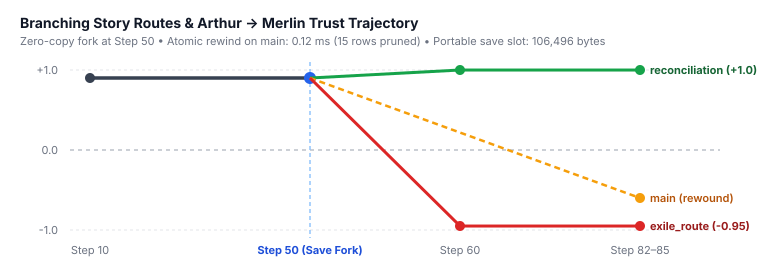

World Element,main (before rewind),reconciliation_route
char_arthur,"mood=furious, location_id=loc_council_chamber, (Discovered Merlin concealed the dragon prophecy)","mood=calm, location_id=loc_council_chamber"
char_arthur:stance->char_merlin,"register=informal, tone=furious, trust=-0.6, (Betrayed over the concealed prophecy)","register=formal, tone=grateful, trust=1.0, (Merlin shared the prophecy voluntarily)"
char_mordred,"mood=watchful, location_id=loc_council_chamber","mood=watchful, location_id=loc_courtyard"
char_arthur:possesses->item_dragon_seal,present only in main,absent
char_merlin:possesses->item_dragon_seal,absent,present only in reconciliation_route


In [7]:
#@title 🔍 Click to inspect code: Step 6 — Branching Routes, Save-Slot Reload, Rollback & Compaction
# 1) Fork TWO zero-copy routes from Step 50
engine.branch(at_step=50, name="reconciliation_route", switch=False)
engine.branch(at_step=50, name="exile_route", switch=False)
assert engine.active_timeline == "main"

# Route A: reconciliation_route (using concurrency-safe TimelineSession + step_transaction)
recon_sess = engine.session("reconciliation_route")
with recon_sess.step_transaction(step=60, text="Merlin reveals the prophecy to Arthur.") as tx:
    assert any(e.entity_id == "char_arthur" for e in tx.context.entities)
    tx.commit(
        delta=StepDelta(
            edges=[
                EdgeDelta(
                    source_id="char_arthur",
                    target_id="char_merlin",
                    relation_type="stance",
                    state={"register": "formal", "tone": "grateful", "trust": 1.0},
                    caused_by_episode_id="ep_step60_honest_counsel",
                    reason="Merlin shared the prophecy voluntarily",
                )
            ],
            episodes=[
                EpisodeRecord(
                    episode_id="ep_step60_honest_counsel",
                    predicate="revelation",
                    summary="Merlin voluntarily revealed the dragon prophecy to Arthur before battle.",
                    participants={"char_merlin": "actor", "char_arthur": "target"},
                    witnesses=["char_merlin", "char_arthur"],
                    location_id="loc_council_chamber",
                    salience=8.8,
                )
            ],
        )
    )

# Add 2 low-salience filler beats on reconciliation_route to demonstrate compaction
for fill_step, fill_id, fill_txt in [
    (65, "ep_step65_supply_check", "Arthur and Merlin reviewed routine arrow and timber inventories."),
    (70, "ep_step70_watch_rotation", "The castle guard rotated shifts along the eastern battlements."),
]:
    recon_sess.commit_step(
        step=fill_step,
        delta=StepDelta(
            chapter_id="ch02",
            episodes=[
                EpisodeRecord(
                    episode_id=fill_id,
                    predicate="routine",
                    summary=fill_txt,
                    participants={"char_arthur": "actor"},
                    witnesses=["char_arthur", "char_merlin"],
                    chapter_id="ch02",
                    salience=2.5,
                )
            ],
        ),
    )

# Route B: exile_route (using context-scoped use_timeline)
with engine.use_timeline("exile_route"):
    engine.commit_step(
        step=60,
        delta=StepDelta(
            entities=[EntityDelta(entity_id="char_arthur", state={"mood": "cold"}, caused_by_episode_id="ep_step60_exile", reason="Banished Merlin from Camelot")],
            edges=[EdgeDelta(source_id="char_arthur", target_id="char_merlin", relation_type="stance", state={"register": "informal", "tone": "cold", "trust": -0.95}, caused_by_episode_id="ep_step60_exile", reason="Arthur exiled Merlin on suspicion of treason")],
            episodes=[EpisodeRecord(episode_id="ep_step60_exile", predicate="banishment", summary="Arthur stripped Merlin of his staff and banished him from Camelot.", participants={"char_arthur": "actor", "char_merlin": "target"}, witnesses=["char_arthur", "char_merlin", "char_mordred"], location_id="loc_council_chamber", salience=9.5)],
        ),
    )

# 2) Diff 'main' vs 'reconciliation_route' at Step 85
diff_85 = engine.diff_timelines("main", "reconciliation_route", at_step=85)

# 3) Export standalone .sqlite save slot & reload it in a fresh engine
with tempfile.TemporaryDirectory() as tmpdir:
    slot_path = engine.export_snapshot(Path(tmpdir) / "save_slot_reconciliation.sqlite", at_step=85, timeline_id="reconciliation_route")
    slot_bytes = slot_path.stat().st_size
    reloaded = CanonArcEngine(slot_path, preset=InteractiveFictionPreset())
    reloaded_ctx = reloaded.retrieve_context(step=85, mentions=["Arthur", "Merlin"])
    reloaded_edge = next(e for e in reloaded_ctx.active_edges if e.source_id == "char_arthur" and e.target_id == "char_merlin")
    assert reloaded_edge.state["trust"] == 1.0 and reloaded_edge.state["tone"] == "grateful"
    reloaded.close()

# 4) Benchmark atomic < 1ms rewind on 'main' back to Step 50
t0 = time.perf_counter()
deleted_rows = engine.rollback_to(step=50, timeline_id="main")
rollback_ms = (time.perf_counter() - t0) * 1000.0

# 5) Compact low-salience filler beats into one Act II summary
consolidated = recon_sess.consolidate_episodes(
    step=75,
    before_step=75,
    max_salience=4.0,
    summary="During quiet preparations after Merlin's counsel, Camelot checked supplies and rotated guards.",
    chapter_id="ch02",
)
assert consolidated is not None

# Switch to reconciliation_route for Step 7's live AI turn
engine.checkout("reconciliation_route")

render_route_tree_and_diff(
    diff_85,
    rollback_ms,
    deleted_rows,
    slot_bytes,
    [t.timeline_id for t in engine.list_timelines()],
    consolidated.summary,
)

## Step 7: Putting It All Together — A Live AI-Powered RPG Turn

Up to now, we fed scripted story beats so you could see each feature clearly. In a real game, **the AI writes the scene and `canonarc` updates the world automatically!**

### What Happens in One Live Turn (`play_rpg_turn`, Step 90 on `reconciliation_route`)
> **Player / Scene Prompt:** *"Arthur and Merlin move into the War Room to plan against the dragon. Mordred bursts through the oak doors, furious at being excluded from the council, and snaps at Arthur with open hostility and no royal formality."*

1. **Retrieve:** `canonarc` fetches the current `reconciliation_route` context (Arthur is `calm`, trusts Merlin `+1.0`).
2. **Generate Prose:** DeepSeek Flash writes 3–4 vivid sentences of narration and dialogue honoring the world state.
3. **Auto-Extract & Save (`CachedDeltaExtractor`):** `canonarc` reads the generated prose and automatically extracts who moved to the War Room, Mordred's new mood & hostility, and the new memory episode—**no manual JSON writing required!**
4. **Harvest Voice Quotes:** Any strong dialogue Mordred spoke is automatically harvested and gated into his Voice Bank.
5. **Instant `$0.00` Cache Replay:** We also replay the exact same beat on a sibling branch to show `CachedDeltaExtractor` hitting its disk cache for `$0.00`.

> 💡 **Want $0.00 Local Inference?** Because all extractors share the same interface, swapping DeepSeek for a local model in LM Studio (`OpenAICompatibleExtractor.from_lmstudio()`) or Gemini (`from_gemini()`) is a single-line change.

In [8]:
#@title 🔍 Click to inspect code: Step 7 — Closed-Loop Live RPG Turn Runner + Cached Extraction
def play_rpg_turn(
    engine: CanonArcEngine,
    *,
    step: int,
    player_action: str,
    extractor: CachedDeltaExtractor | None = None,
) -> dict[str, Any]:
    """Closed-loop RPG turn: Retrieve -> Generate Prose -> Extract & Commit -> Harvest Voice."""
    with engine.step_transaction(step=step, text=player_action) as tx:
        prompt_ctx = engine.format_context(tx.context)

        # 1) Generate narrative prose grounded in canonarc's 6-tier context
        fallback_prose = (
            "Arthur and Merlin stepped into the war room to inspect the dragon maps. "
            "Moments later, Mordred burst through the oak doors, furious that he had been shut out of the council. "
            '"You conspire behind closed doors while I guard the gates in the freezing rain, Arthur!" '
            "Mordred snapped at the King, dropping all royal formality in his rage."
        )
        scene_prose, gen_usage = call_deepseek_flash(
            [
                {
                    "role": "system",
                    "content": (
                        "You are an interactive-fiction narrator. Write 3-4 vivid sentences continuing the scene: "
                        "explicitly narrate Arthur and Merlin entering the War Room, then have Mordred burst in and speak "
                        'at least one 15+ word quoted dialogue line introduced directly by Mordred (e.g. Mordred snapped, "..."). '
                        "Strictly obey character moods, stances, and who knows what from the provided context."
                    ),
                },
                {"role": "user", "content": f"{prompt_ctx}\n\n### Player / Scene Action:\n{player_action}"},
            ],
            temperature=0.3,
            fallback_text=fallback_prose,
        )

        # 2) Auto-extract world updates from the prose (live LLM or offline fallback)
        if extractor is not None:
            delta = tx.extract_and_commit(scene_prose, extractor=extractor)
        else:
            delta = StepDelta(
                entities=[
                    EntityDelta(entity_id="char_arthur", state={"location_id": "loc_war_room"}),
                    EntityDelta(entity_id="char_merlin", state={"location_id": "loc_war_room"}),
                    EntityDelta(entity_id="char_mordred", state={"location_id": "loc_war_room", "mood": "furious"}, caused_by_episode_id="ep_step90_mordred_confrontation", reason="Burst into the war room furious at being excluded"),
                ],
                edges=[
                    EdgeDelta(source_id="char_mordred", target_id="char_arthur", relation_type="stance", state={"register": "informal", "tone": "furious", "trust": -0.6}, caused_by_episode_id="ep_step90_mordred_confrontation", reason="Confronted Arthur with open hostility")
                ],
                episodes=[
                    EpisodeRecord(episode_id="ep_step90_mordred_confrontation", predicate="confrontation", summary="Mordred burst into the war room and furiously accused Arthur of conspiring behind closed doors.", participants={"char_mordred": "actor", "char_arthur": "target", "char_merlin": "witness"}, witnesses=["char_arthur", "char_merlin", "char_mordred"], location_id="loc_war_room", salience=8.0)
                ],
            )
            tx.commit(delta=delta)

        # 3) Harvest qualifying dialogue quotes into the Tier 5 Voice Bank
        stance_meta_by_speaker = {
            edge.source_id: {"register": str(edge.state.get("register", "informal")), "tone": str(edge.state.get("tone", "furious"))}
            for edge in delta.edges
            if edge.relation_type == "stance"
        }
        candidates = engine.extract_dialogue_candidates(scene_prose, step=step)
        harvested_exemplars = [
            VoiceExemplar(step=step, speaker_id=c.speaker_id, text=c.text, metadata=stance_meta_by_speaker.get(c.speaker_id, {"register": "informal", "tone": "furious"}), quality_score=8.9)
            for c in candidates
            if c.speaker_id is not None
        ]
        if harvested_exemplars:
            tx.commit(delta=delta, exemplars=harvested_exemplars)

    return {"prose": scene_prose, "harvested": harvested_exemplars, "delta": delta, "gen_usage": gen_usage}


player_choice_step90 = (
    "Arthur and Merlin move into the War Room to plan against the dragon. "
    "Mordred bursts through the oak doors, furious at being excluded from the council, "
    "and snaps at Arthur with open hostility and no royal formality."
)

ext_usage_dict: dict[str, Any] = {}
cache_stats = {"hits": 0, "misses": 0}

with tempfile.TemporaryDirectory() as cache_dir:
    cached_ext = (
        CachedDeltaExtractor(OpenAICompatibleExtractor.from_deepseek(model=DEEPSEEK_MODEL, temperature=0.0), cache_dir=Path(cache_dir))
        if HAS_LIVE_LLM
        else None
    )
    turn_result = play_rpg_turn(engine, step=90, player_action=player_choice_step90, extractor=cached_ext)

    # Replay the identical turn on a forked branch -> instant $0.00 cache hit!
    if cached_ext is not None:
        engine.branch(at_step=89, name="replay_cache_demo", switch=False)
        with engine.use_timeline("replay_cache_demo"):
            with engine.step_transaction(step=90, text=player_choice_step90) as tx_replay:
                _ = tx_replay.extract_and_commit(turn_result["prose"], extractor=cached_ext)
        cache_stats = {"hits": cached_ext.cache_hits, "misses": cached_ext.cache_misses}
        assert cache_stats["hits"] == 1 and cache_stats["misses"] == 1
        ext_usage_dict = cached_ext.billable_usage.to_dict(model=DEEPSEEK_MODEL)

# Retrieve Step 91 context to verify the newly extracted world state is live
ctx_91 = engine.retrieve_context(step=91, mentions=["Arthur", "Merlin", "Mordred"])
render_live_turn_report(
    turn_result["prose"],
    len(turn_result["harvested"]),
    turn_result["delta"].model_dump(exclude_defaults=True),
    engine.format_context(ctx_91),
    ext_usage_dict,
    cache_stats,
)

## Step 8: Automated Quality Audit & Flight-Recorder Telemetry

To verify that every guarantee in this guide is backed by real engine invariants (not mocked outputs), we run a **14-point automated audit** covering all 6 tiers, anti-metagaming, branching, portable save reload, `< 1ms` rollback, and our live AI turn—plus print the total token & cost telemetry.

In [9]:
#@title 🔍 Click to inspect code: Step 8 — 14-Point Automated QA Audit & Telemetry Summary
arthur_history = engine.get_history("char_arthur")
mordred_91 = next(e for e in ctx_91.entities if e.entity_id == "char_mordred")

qa_checks = [
    ("Tier 1 & 4: Alias coreference ('the old wizard' -> char_merlin)", any(m.entity_id == "char_merlin" and m.matched_via == "alias" for m in ctx_85.resolved_mentions)),
    ("Tier 2: Spatial location_id auto-discovery & off-screen background_edges", len(room_ctx.background_edges) >= 1),
    ("Tier 2: Artifact handoff (Arthur possesses seal; Merlin no longer does)", any(e.source_id == "char_arthur" and e.relation_type == "possesses" and e.target_id == "item_dragon_seal" for e in ctx_85.active_edges) and not any(e.source_id == "char_merlin" and e.relation_type == "possesses" and e.target_id == "item_dragon_seal" for e in ctx_85.active_edges)),
    ("Tier 3: Windowed prior_state trajectory (furious, was calm at step 0)", arthur_85.prior_state.get("mood") == "calm"),
    ("Tier 3: Flashback isolation (Step 84 flashback did not overwrite Step 85 state)", arthur_85.state["mood"] == "furious" and arthur_merlin_85.state["register"] == "informal"),
    ("Tier 5: 2-stage IngestionGate rejected both gate1 and gate2 separately", {r["stage"] for r in hook.gate_rejections} >= {"gate1", "gate2"}),
    ("Tier 5: Automatic dialogue harvesting + hard-filter fallback note", len(merlin_accepted) == 1 and "register" in fallback_note),
    ("Tier 6: Anti-metagaming POV isolation & private_state redaction", len(mordred_pov_85.episodes) == 0 and merlin_in_mordred_pov.private_state == {}),
    ("Tier 6: Full epistemic spectrum (deceived -> told -> forgotten + pov_mode='all')", "grain rations" in mordred_pov_86.episodes[0].summary and "dragon prophecy" in mordred_pov_87.episodes[0].summary and all(ep.episode_id != "ep_step84_coronation_oath" for ep in merlin_pov_88.episodes) and any(ep.episode_id == "ep_step82_prophecy_dispute" for ep in common_87.episodes)),
    ("Time Travel: Multi-route branch isolation & diff_timelines()", len(diff_85["changed"]) >= 2),
    ("Time Travel: Portable .sqlite save-slot export & fresh-engine reload", reloaded_edge.state["trust"] == 1.0),
    ("Time Travel: Atomic rollback (< 50ms) & episode compaction", deleted_rows > 0 and rollback_ms < 50.0 and consolidated is not None),
    ("Observability: BaseEngineHooks telemetry & get_history()", len(hook.commits) >= 5 and len(hook.branches) >= 2 and len(arthur_history) >= 1),
    ("Closed-Loop Turn: Step 90 extracted state visible at Step 91", mordred_91.state.get("mood") not in (None, "watchful")),
]

for name, passed in qa_checks:
    assert passed, f"QA check failed: {name}"

dlg_cost = dialogue_llm_usage.to_dict(model=DEEPSEEK_MODEL)
total_tokens = dlg_cost["total_tokens"] + ext_usage_dict.get("total_tokens", 0)
total_usd = dlg_cost["cost_estimate"]["total_cost_usd"] + ext_usage_dict.get("cost_estimate", {}).get("total_cost_usd", 0.0)

render_qa_audit(qa_checks, hook, rollback_ms, total_tokens, total_usd, cache_stats)
engine.close()

PASS,Tier 1 & 4: Alias coreference ('the old wizard' -> char_merlin)
PASS,Tier 2: Spatial location_id auto-discovery & off-screen background_edges
PASS,Tier 2: Artifact handoff (Arthur possesses seal; Merlin no longer does)
PASS,"Tier 3: Windowed prior_state trajectory (furious, was calm at step 0)"
PASS,Tier 3: Flashback isolation (Step 84 flashback did not overwrite Step 85 state)
PASS,Tier 5: 2-stage IngestionGate rejected both gate1 and gate2 separately
PASS,Tier 5: Automatic dialogue harvesting + hard-filter fallback note
PASS,Tier 6: Anti-metagaming POV isolation & private_state redaction
PASS,Tier 6: Full epistemic spectrum (deceived -> told -> forgotten + pov_mode='all')
PASS,Time Travel: Multi-route branch isolation & diff_timelines()
PASS,Time Travel: Portable .sqlite save-slot export & fresh-engine reload


---

## Where to Go Next

Now that you've seen how `canonarc` powers an interactive RPG at a high level:

- **Want to copy-paste patterns into your own project?** Expand any collapsed code cell above—every demo cell is self-contained and focused purely on `canonarc` API calls.
- **Explore other domains in `examples/`:**
  - `02_literary_translation.ipynb` — Long-form literary translation with pronoun/register tracking (`Vi` ↔ `ti`) and voice consistency.
  - `03_multi_agent_simulation.ipynb` — Autonomous multi-agent simulations with facades, custom policies, and parallel counterfactuals.
  - `04_mystery_and_social_deduction.ipynb` — Disguises, hidden identities, and social deduction games.